# 03 — VAE: detección de anomalías viales

Este notebook **no entrena**: lee los resultados generados por

```powershell
python -m src.data.cache_images --size 128
python -m src.data.cache_images --size 512
python -m src.models.train_vae --config configs/vae/vae_base.yaml
python -m src.models.train_vae --config configs/vae/vae_patch512.yaml
```

| Corrida | Qué ve el VAE |
|---|---|
| `vae_base` | la imagen completa a 128×128 |
| `vae_patch512` | la imagen a 512×512 cortada en 64 parches de 64×64 (cada parche por separado) |

Ambas se entrenan solo con imágenes de `train` **sin daño anotado** (`has_any_damage == 0`) y eligen el checkpoint
con la pérdida (β = 1) en las imágenes sin daño de `val`, sin usar etiquetas. Cada una produce tres scores:

- **global**: error cuadrático medio de toda la imagen;
- **patch**: máximo del error promediado por celda (16×16 en `vae_base`, 64×64 en `vae_patch512`);
- **patch_norm**: máximo de `(error de la celda − media de esa posición) / desviación de esa posición`, con
  media y desviación calculadas solo en imágenes de `train` sin daño. Resta lo que "siempre" cuesta reconstruir
  en cada posición (cielo, postes, capó).

Para cada score el threshold maximiza F1 de D40 en `val`; el score principal es el de mayor PR-AUC en `val`.
Todo queda fijo para `test_id`, `test_ood` (Norway) y `test_perspective` (China_Drone).
Las corridas `_limitN` son pruebas y se ignoran.

**Criterio de éxito (fijado antes de ver resultados):** PR-AUC de D40 en `val` claramente por encima de la
prevalencia y AUROC `no_damage_vs_pothole` > 0.6 **dentro** de los países que tienen ambos grupos.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
RESULTS = PROJECT_ROOT / "reports" / "experiments" / "vae"
SPLITS = ["val", "test_id", "test_ood", "test_perspective"]
GROUPS = ["no_damage", "other", "pothole"]

runs = {}
for folder in sorted(RESULTS.glob("*")) if RESULTS.exists() else []:
    if (folder / "metrics.json").exists() and "_limit" not in folder.name:
        runs[folder.name] = dict(
            config=yaml.safe_load((folder / "config.yaml").read_text(encoding="utf-8")),
            metrics=json.loads((folder / "metrics.json").read_text(encoding="utf-8")),
            history=pd.read_csv(folder / "history.csv"),
            predictions=pd.read_csv(folder / "predictions.csv"),
        )
print("Corridas encontradas:", list(runs) or "ninguna todavía")

Corridas encontradas: ['vae_base', 'vae_patch512']


## 1. Configuración registrada

In [2]:
keys = ["latent", "image_size", "patch_size", "patch", "batch_size", "epochs", "lr", "patience", "warmup_epochs",
        "std_floor_frac", "optimizer", "best_epoch", "train_images", "val_no_damage_images", "image_source", "seed",
        "dataset_version", "splits_sha256"]
pd.DataFrame({name: {k: run["config"].get(k) for k in keys} for name, run in runs.items()})

,vae_base,vae_patch512
latent,128,128
image_size,128,512
patch_size,None,64
patch,16,64
batch_size,64,8
epochs,50,30
lr,0.001,0.001
patience,8,8
warmup_epochs,5,5
std_floor_frac,0.1,0.1


## 2. Curvas de entrenamiento (una figura por corrida)

La pérdida de `val` es solo sobre imágenes sin daño y siempre con β = 1; mientras β < 1 (warmup) no se elige
checkpoint. Las pérdidas absolutas **no** son comparables entre corridas (cada imagen suma 49 mil píxeles en
`vae_base` y 786 mil en `vae_patch512`). La PR-AUC de `val` se registra por época pero no interviene en la selección.

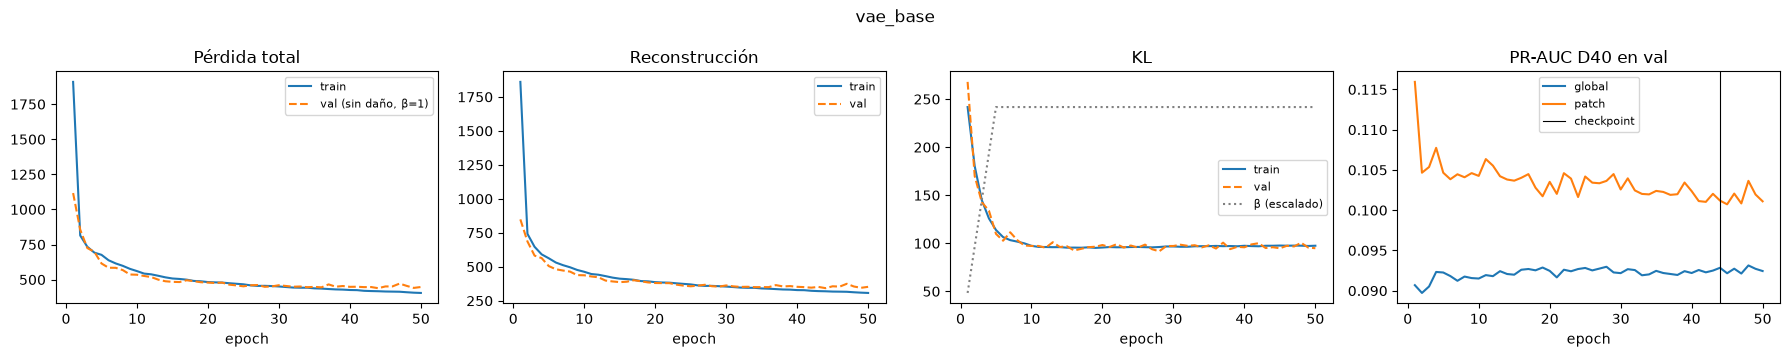

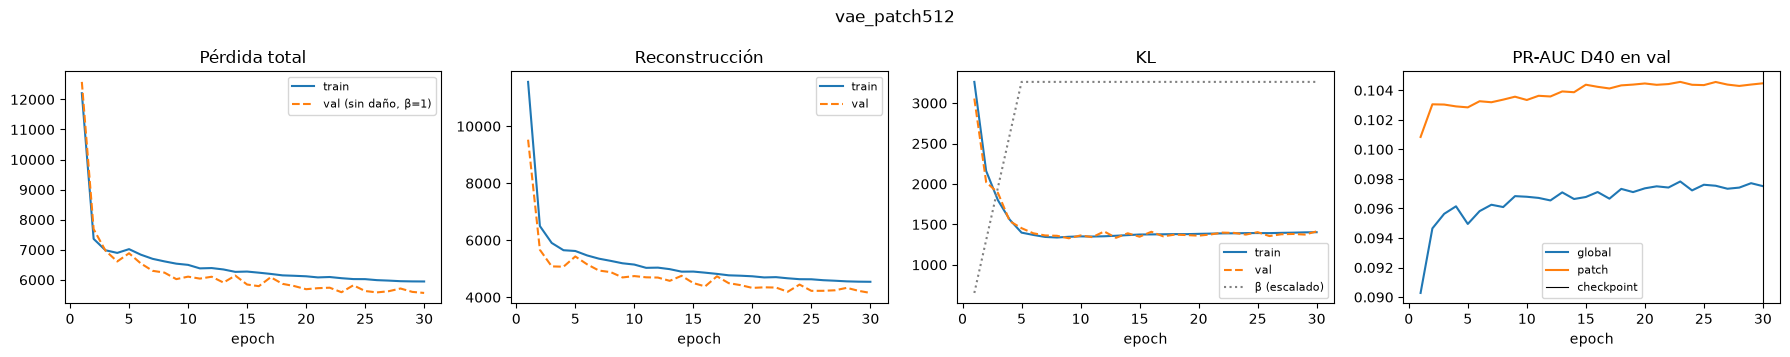

In [3]:
for name, run in runs.items():
    h = run["history"]
    fig, axes = plt.subplots(1, 4, figsize=(18, 3.6))
    axes[0].plot(h.epoch, h.train_loss, label="train")
    axes[0].plot(h.epoch, h.val_loss, "--", label="val (sin daño, β=1)")
    axes[1].plot(h.epoch, h.train_recon, label="train")
    axes[1].plot(h.epoch, h.val_recon, "--", label="val")
    axes[2].plot(h.epoch, h.train_kl, label="train")
    axes[2].plot(h.epoch, h.val_kl, "--", label="val")
    axes[2].plot(h.epoch, h.beta * h.train_kl.max(), ":", color="gray", label="β (escalado)")
    axes[3].plot(h.epoch, h.val_pr_auc_global, label="global")
    axes[3].plot(h.epoch, h.val_pr_auc_patch, label="patch")
    axes[3].axvline(run["metrics"]["best_epoch"], color="k", lw=0.8, label="checkpoint")
    for ax, title in zip(axes, ["Pérdida total", "Reconstrucción", "KL", "PR-AUC D40 en val"]):
        ax.set(title=title, xlabel="epoch")
        ax.legend(fontsize=8)
    fig.suptitle(name)
    plt.tight_layout()

## 3. Métricas D40: corridas × scores

La PR-AUC se lee junto a la prevalencia (PR-AUC de un clasificador aleatorio). `f1_trivial` = 2p / (1 + p) es el
F1 de marcar todo como D40: un F1 que no lo supera no aporta nada.

In [4]:
rows = []
for name, run in runs.items():
    m = run["metrics"]
    print(f"{name}: score principal = {m['primary_score']}, PR-AUC val = "
          + ", ".join(f"{k} {v:.4f}" for k, v in m["val_pr_auc"].items()))
    for split, by_score in m["splits"].items():
        for score, values in by_score.items():
            p = values["prevalence"]
            rows.append(dict(experiment=name, score=score, split=split, prevalence=p, pr_auc=values["pr_auc"],
                             f1=values["f1"], f1_trivial=2 * p / (1 + p), recall=values["recall"],
                             precision=values["precision"]))
table = pd.DataFrame(rows)
table.pivot(index=["experiment", "score"], columns="split", values=["pr_auc", "f1"]).reindex(
    columns=SPLITS, level=1).round(4) if not table.empty else "Sin resultados todavía"

vae_base: score principal = patch, PR-AUC val = global 0.0928, patch 0.1012, patch_norm 0.0977
vae_patch512: score principal = patch, PR-AUC val = global 0.0975, patch 0.1045, patch_norm 0.0974


pr_auc                                        f1  \
split                       val test_id test_ood test_perspective     val   
experiment   score                                                          
vae_base     global      0.0928  0.0947   0.0360           0.0235  0.2181   
             patch       0.1012  0.1083   0.0349           0.0249  0.2174   
             patch_norm  0.0977  0.1014   0.0310           0.0242  0.2156   
vae_patch512 global      0.0975  0.0997   0.0416           0.0198  0.2156   
             patch       0.1045  0.1054   0.0484           0.0216  0.2157   
             patch_norm  0.0974  0.0978   0.0283           0.0217  0.2155   

                                                           
split                   test_id test_ood test_perspective  
experiment   score                                         
vae_base     global      0.2171   0.0608           0.0507  
             patch       0.2169   0.0608           0.0539  
             patch_norm  0.2146   0.0608           0.0521  
vae_patch512 global      0.2150   0.0608           0.0522  
             patch       0.2146   0.0608           0.0585  
             patch_norm  0.2149   0.0608           0.0527

,prevalence,f1_trivial
split,,
val,0.1208,0.2155
test_id,0.1203,0.2147
test_ood,0.0314,0.0608
test_perspective,0.0267,0.0519


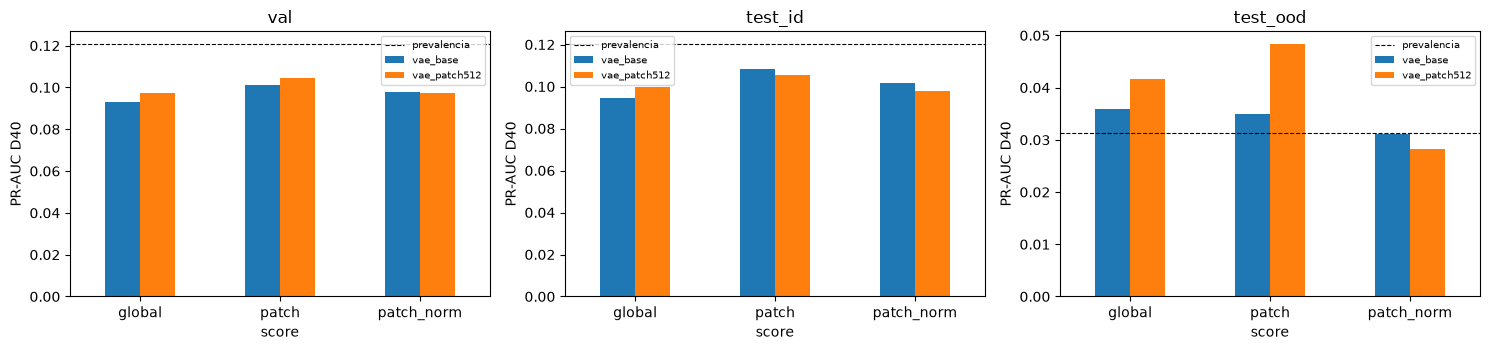

In [5]:
if not table.empty:
    display(table.groupby("split")[["prevalence", "f1_trivial"]].first().reindex(SPLITS).round(4))
    order = ["val", "test_id", "test_ood"]
    fig, axes = plt.subplots(1, len(order), figsize=(5 * len(order), 3.6), sharey=False)
    for ax, split in zip(axes, order):
        part = table[table.split == split].pivot(index="score", columns="experiment", values="pr_auc")
        part.plot.bar(ax=ax, rot=0)
        ax.axhline(table[table.split == split].prevalence.iloc[0], color="k", ls="--", lw=0.8, label="prevalencia")
        ax.set(title=split, ylabel="PR-AUC D40")
        ax.legend(fontsize=7)
    plt.tight_layout()

## 4. ¿Detecta baches o cualquier daño?

Score principal de cada corrida. `flagged_rate` es la proporción sobre el threshold: en `no_damage` y `other` son
falsos positivos, en `pothole` es el recall. AUROC por pares: 0.5 = no separa; > 0.5 = el segundo grupo puntúa más.

In [6]:
for name, run in runs.items():
    primary = run["metrics"]["primary_score"]
    print(f"{name} ({primary})")
    rows = [dict(split=split, group=group, **values)
            for split, report in run["metrics"]["breakdown"].items()
            for group, values in report[primary]["groups"].items()]
    display(pd.DataFrame(rows).pivot(index="group", columns="split", values=["n", "median", "flagged_rate"])
            .reindex(columns=SPLITS, level=1).reindex(GROUPS).round(4))
    rows = [dict(split=split, score=score, pair=pair, auroc=values["auroc"])
            for split, report in run["metrics"]["breakdown"].items()
            for score, by_score in report.items()
            for pair, values in by_score["pairwise_auroc"].items()]
    display(pd.DataFrame(rows).pivot(index=["score", "pair"], columns="split", values="auroc")
            .reindex(columns=SPLITS).round(3))

vae_base (patch)


n                                    median                   \
split         val test_id test_ood test_perspective     val test_id test_ood   
group                                                                          
no_damage   970.0   971.0   5247.0              5.0  0.0331  0.0325   0.0393   
other      2699.0  2701.0   2658.0           2332.0  0.0446  0.0441   0.0473   
pothole     504.0   502.0    256.0             64.0  0.0341  0.0367   0.0442   

                           flagged_rate                                    
split     test_perspective          val test_id test_ood test_perspective  
group                                                                      
no_damage           0.0353       0.9979  1.0000      1.0           1.0000  
other               0.0142       0.9830  0.9826      1.0           0.9305  
pothole             0.0106       0.9980  1.0000      1.0           0.9688

split                              val  test_id  test_ood  test_perspective
score      pair                                                            
global     no_damage_vs_other    0.702    0.713     0.670             0.267
           no_damage_vs_pothole  0.519    0.557     0.619             0.256
           other_vs_pothole      0.334    0.346     0.435             0.396
patch      no_damage_vs_other    0.634    0.655     0.627             0.239
           no_damage_vs_pothole  0.506    0.556     0.586             0.225
           other_vs_pothole      0.386    0.408     0.456             0.415
patch_norm no_damage_vs_other    0.674    0.697     0.533             0.304
           no_damage_vs_pothole  0.531    0.574     0.502             0.234
           other_vs_pothole      0.365    0.380     0.469             0.408

vae_patch512 (patch)


n                                    median                   \
split         val test_id test_ood test_perspective     val test_id test_ood   
group                                                                          
no_damage   970.0   971.0   5247.0              5.0  0.0191  0.0189   0.0135   
other      2699.0  2701.0   2658.0           2332.0  0.0238  0.0234   0.0161   
pothole     504.0   502.0    256.0             64.0  0.0191  0.0191   0.0169   

                           flagged_rate                                    
split     test_perspective          val test_id test_ood test_perspective  
group                                                                      
no_damage           0.0063       0.9959  0.9938      1.0           0.6000  
other               0.0061       1.0000  1.0000      1.0           0.7401  
pothole             0.0053       1.0000  0.9980      1.0           0.8438

split                              val  test_id  test_ood  test_perspective
score      pair                                                            
global     no_damage_vs_other    0.672    0.676     0.610             0.438
           no_damage_vs_pothole  0.524    0.541     0.616             0.388
           other_vs_pothole      0.361    0.362     0.507             0.382
patch      no_damage_vs_other    0.591    0.591     0.607             0.461
           no_damage_vs_pothole  0.486    0.497     0.624             0.434
           other_vs_pothole      0.395    0.400     0.525             0.427
patch_norm no_damage_vs_other    0.741    0.728     0.345             0.478
           no_damage_vs_pothole  0.580    0.577     0.391             0.409
           other_vs_pothole      0.338    0.343     0.549             0.432

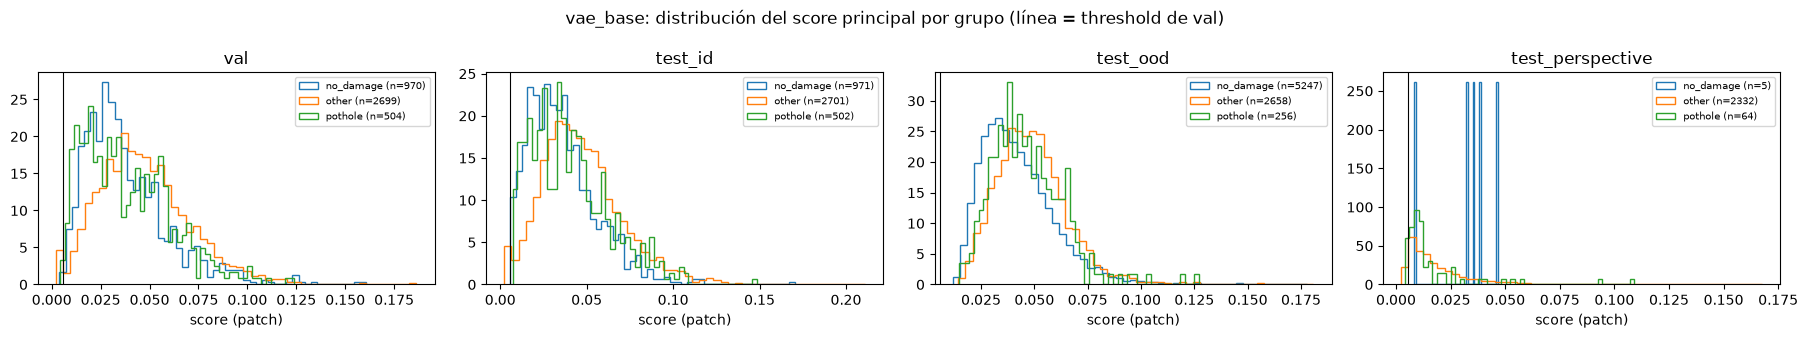

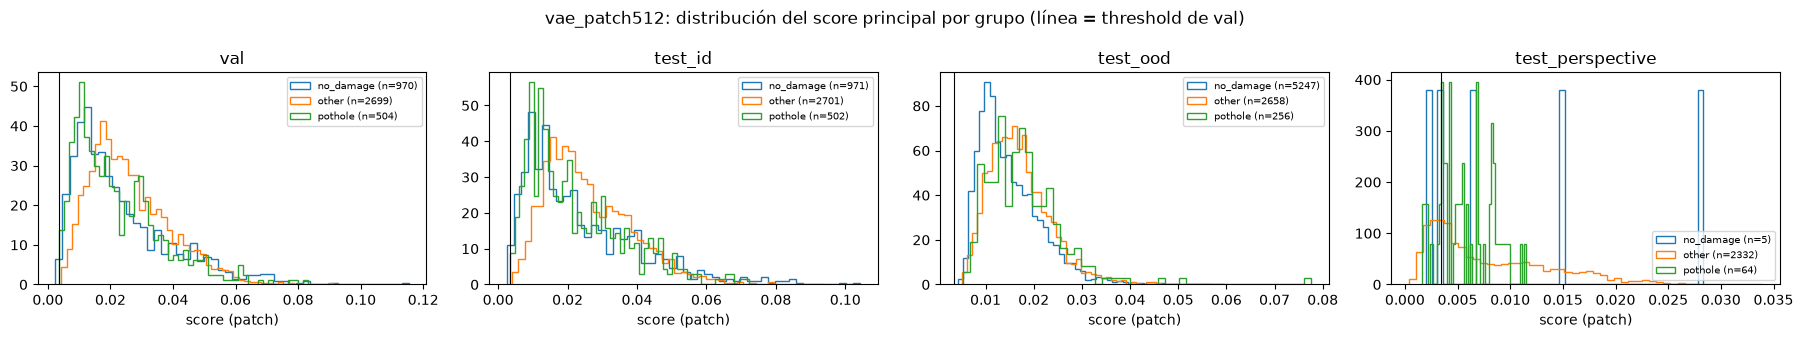

In [7]:
for name, run in runs.items():
    predictions = run["predictions"]
    fig, axes = plt.subplots(1, len(SPLITS), figsize=(4.5 * len(SPLITS), 3.4))
    for ax, split in zip(axes, SPLITS):
        part = predictions[predictions.split == split]
        for group in GROUPS:
            values = part.loc[part.group == group, "y_score"]
            if len(values):
                ax.hist(values, bins=50, density=True, histtype="step", label=f"{group} (n={len(values)})")
        ax.axvline(part.threshold.iloc[0], color="k", lw=0.8)
        ax.set(title=split, xlabel=f"score ({run['metrics']['primary_score']})")
        ax.legend(fontsize=7)
    fig.suptitle(f"{name}: distribución del score principal por grupo (línea = threshold de val)")
    plt.tight_layout()

## 5. Comparación dentro de cada país

Las imágenes sin daño de `train` y `val` vienen solo de Czech, India y Japan; United_States y China_MotorBike no
tienen ninguna. Un score alto en esos países puede deberse al dominio y no al daño, así que la comparación limpia
es dentro de cada país que tiene los dos grupos. Esta tabla es la que decide el criterio de éxito.

In [8]:
rows = []
for name, run in runs.items():
    for split in ["val", "test_id"]:
        for score, report in run["metrics"]["breakdown"][split].items():
            for country, values in report["by_country"].items():
                if values["n"]["no_damage"] and values["n"]["pothole"]:
                    rows.append(dict(experiment=name, score=score, split=split, country=country,
                                     n_pothole=values["n"]["pothole"], pr_auc_D40=values["pr_auc_D40"],
                                     auroc_no_damage_vs_pothole=values["pairwise_auroc"]["no_damage_vs_pothole"]["auroc"],
                                     auroc_other_vs_pothole=values["pairwise_auroc"]["other_vs_pothole"]["auroc"]))
within = pd.DataFrame(rows)
within.pivot(index=["experiment", "score"], columns=["split", "country"],
             values="auroc_no_damage_vs_pothole").round(3) if not within.empty else "Sin resultados todavía"

split                      val               test_id              
country                  Czech  India  Japan   Czech  India  Japan
experiment   score                                                
vae_base     global      0.596  0.386  0.325   0.532  0.467  0.365
             patch       0.664  0.388  0.360   0.585  0.459  0.416
             patch_norm  0.635  0.419  0.347   0.507  0.489  0.428
vae_patch512 global      0.576  0.405  0.311   0.534  0.477  0.346
             patch       0.683  0.429  0.323   0.590  0.466  0.320
             patch_norm  0.640  0.495  0.391   0.562  0.536  0.404

## 6. ¿Con qué otros daños se confunde?

Imágenes **sin D40**, separadas por cada clase anotada (score principal). Una imagen con varias clases cuenta en
cada una. `flagged_rate` = falsos positivos con el threshold de `val`.

In [9]:
for name, run in runs.items():
    primary = run["metrics"]["primary_score"]
    print(f"{name} ({primary})")
    rows = [dict(split=split, damage=damage, **values)
            for split, report in run["metrics"]["breakdown"].items()
            for damage, values in report[primary]["other_damage_classes"].items()]
    display(pd.DataFrame(rows).pivot(index="damage", columns="split", values=["n", "flagged_rate"])
            .reindex(columns=SPLITS, level=1).round(4))

vae_base (patch)


n                                   flagged_rate          \
split           val test_id test_ood test_perspective          val test_id   
damage                                                                       
Block crack     NaN     NaN      NaN              3.0          NaN     NaN   
D00          1433.0  1359.0   2365.0           1022.0       0.9714  0.9706   
D01            12.0    16.0      NaN              NaN       1.0000  1.0000   
D10           799.0   798.0    926.0           1012.0       0.9737  0.9812   
D11             4.0     4.0      NaN              NaN       1.0000  1.0000   
D20           959.0   953.0    268.0            257.0       0.9990  0.9948   
D43            91.0   113.0      NaN              NaN       1.0000  1.0000   
D44           571.0   576.0      NaN              NaN       1.0000  1.0000   
D50           323.0   334.0      NaN              NaN       1.0000  1.0000   
Repair         14.0    18.0      NaN            573.0       1.0000  1.0000   

                                       
split       test_ood test_perspective  
damage                                 
Block crack      NaN           1.0000  
D00              1.0           0.9139  
D01              NaN              NaN  
D10              1.0           0.9565  
D11              NaN              NaN  
D20              1.0           0.9183  
D43              NaN              NaN  
D44              NaN              NaN  
D50              NaN              NaN  
Repair           NaN           0.9127

vae_patch512 (patch)


n                                   flagged_rate          \
split           val test_id test_ood test_perspective          val test_id   
damage                                                                       
Block crack     NaN     NaN      NaN              3.0          NaN     NaN   
D00          1433.0  1359.0   2365.0           1022.0          1.0     1.0   
D01            12.0    16.0      NaN              NaN          1.0     1.0   
D10           799.0   798.0    926.0           1012.0          1.0     1.0   
D11             4.0     4.0      NaN              NaN          1.0     1.0   
D20           959.0   953.0    268.0            257.0          1.0     1.0   
D43            91.0   113.0      NaN              NaN          1.0     1.0   
D44           571.0   576.0      NaN              NaN          1.0     1.0   
D50           323.0   334.0      NaN              NaN          1.0     1.0   
Repair         14.0    18.0      NaN            573.0          1.0     1.0   

                                       
split       test_ood test_perspective  
damage                                 
Block crack      NaN           0.6667  
D00              1.0           0.7632  
D01              NaN              NaN  
D10              1.0           0.8024  
D11              NaN              NaN  
D20              1.0           0.6965  
D43              NaN              NaN  
D44              NaN              NaN  
D50              NaN              NaN  
Repair           NaN           0.6300

## 7. Error típico por posición (`patch_norm`)

Media y desviación del error por celda en imágenes de `train` sin daño, con el checkpoint elegido. Celdas con
media alta son las que el VAE siempre reconstruye mal; `patch_norm` las descuenta.

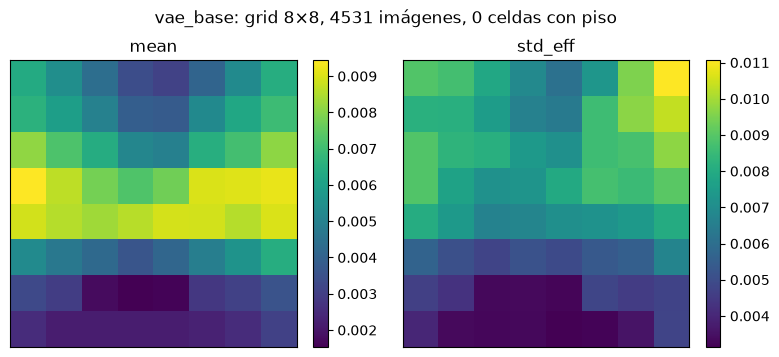

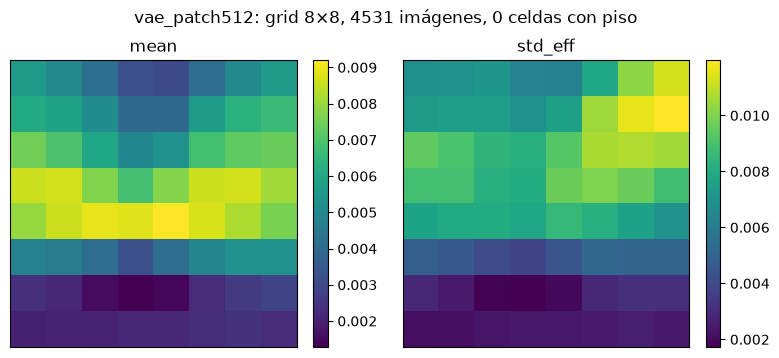

In [10]:
for name, run in runs.items():
    stats = run["metrics"].get("position_stats")
    if not stats:
        continue
    rows, cols = stats["grid"]
    fig, axes = plt.subplots(1, 2, figsize=(8, 3.6))
    for ax, key in zip(axes, ["mean", "std_eff"]):
        image = ax.imshow(np.array(stats[key]).reshape(rows, cols), cmap="viridis")
        fig.colorbar(image, ax=ax, fraction=0.046)
        ax.set(title=key, xticks=[], yticks=[])
    fig.suptitle(f"{name}: grid {rows}×{cols}, {stats['n_images']} imágenes, {stats['n_floored']} celdas con piso")
    plt.tight_layout()

## 8. Reconstrucciones y mapas de error

Ejemplos de `val` con el checkpoint elegido: original, reconstrucción y error por píxel. Se muestran las dos
imágenes con mayor score principal de cada grupo; en las de D40 se dibujan las cajas de `annotations.csv`
escaladas al tamaño de entrada. El mapa de error no es una segmentación.

In [11]:
import sys

import torch
from matplotlib.patches import Rectangle

sys.path.insert(0, str(PROJECT_ROOT))  # para importar src desde notebooks/
from src.data.cache_images import cache_root, cached_frame
from src.data.dataset import DATASET_ROOT, PotholeDataset, build_transforms, load_split_frame
from src.models.vae import build_vae, error_map

annotations = pd.read_csv(PROJECT_ROOT / "data" / "manifests" / "annotations.csv")
frame = load_split_frame(["val"]).set_index("sample_id")
for name, run in runs.items():
    config, predictions = run["config"], run["predictions"]
    checkpoint = PROJECT_ROOT / "checkpoints" / "vae" / name / "best.pt"
    if not checkpoint.exists():
        print(f"{name}: falta {checkpoint.relative_to(PROJECT_ROOT)} (los checkpoints no van a Git)")
        continue
    size = config["image_size"]
    model = build_vae(config["latent"], size, config.get("patch_size"))
    model.load_state_dict(torch.load(checkpoint, map_location="cpu", weights_only=True)["model"])
    model.eval()
    val = predictions[predictions.split == "val"]
    picks = val.sort_values("y_score", ascending=False).groupby("group").head(2).sort_values("group")
    rows = frame.loc[picks.sample_id].reset_index()
    root = cache_root(size) if config["use_cache"] else DATASET_ROOT
    images = cached_frame(rows) if config["use_cache"] else rows
    dataset = PotholeDataset(images, build_transforms(size=size, normalize=False), root)
    fig, axes = plt.subplots(len(rows), 3, figsize=(9, 3 * len(rows)))
    for i, (_, row) in enumerate(rows.iterrows()):
        image = dataset[i][0].unsqueeze(0)
        with torch.no_grad():
            recon = model(image)[0]
        errors = error_map(image, recon)[0, 0]
        score = picks.set_index("sample_id").loc[row.sample_id]
        axes[i, 0].imshow(image[0].permute(1, 2, 0))
        axes[i, 1].imshow(recon[0].permute(1, 2, 0).clamp(0, 1))
        axes[i, 2].imshow(errors, cmap="inferno")
        scale_x, scale_y = size / row.width, size / row.height
        for box in annotations[(annotations.sample_id == row.sample_id) & (annotations["class"] == "D40")].itertuples():
            for ax in (axes[i, 0], axes[i, 2]):
                ax.add_patch(Rectangle((box.xmin * scale_x, box.ymin * scale_y), box.bbox_width * scale_x,
                                       box.bbox_height * scale_y, fill=False, edgecolor="cyan", lw=1.2))
        axes[i, 0].set_title(f"{score.group} · {row.country}", fontsize=8)
        axes[i, 2].set_title(f"score {score.y_score:.4f}", fontsize=8)
        for ax in axes[i]:
            ax.axis("off")
    fig.suptitle(f"{name}: original · reconstrucción · error")
    plt.tight_layout()

vae_base: falta checkpoints\vae\vae_base\best.pt (los checkpoints no van a Git)
vae_patch512: falta checkpoints\vae\vae_patch512\best.pt (los checkpoints no van a Git)


## 9. Latencia (batch 1, solo forward con z = μ; no incluye el cálculo del score)

In [12]:
pd.DataFrame({name: run["metrics"]["latency"] for name, run in runs.items()}).T

,batch_size,image_size,patch_size,includes,cuda_ms,cpu_ms
vae_base,1,128,None,"forward pass only (z = mu), preprocessed input...",2.28355,9.3208
vae_patch512,1,512,64,"forward pass only (z = mu), preprocessed input...",5.1581,95.5705


## 10. Comparación con ResNet

Misma métrica (PR-AUC de D40) sobre los mismos splits. Solo aparece si ya existen resultados de ResNet.

In [13]:
resnet_rows = []
for folder in sorted((PROJECT_ROOT / "reports" / "experiments" / "resnet").glob("*")):
    if (folder / "metrics.json").exists() and "_limit" not in folder.name:
        metrics = json.loads((folder / "metrics.json").read_text(encoding="utf-8"))
        resnet_rows += [dict(model=f"resnet · {folder.name}", split=split, pr_auc=values["pr_auc"], f1=values["f1"])
                        for split, values in metrics["splits"].items()]
vae_rows = [dict(model=f"vae · {name} ({run['metrics']['primary_score']})", split=split,
                 pr_auc=by_score[run["metrics"]["primary_score"]]["pr_auc"],
                 f1=by_score[run["metrics"]["primary_score"]]["f1"])
            for name, run in runs.items() for split, by_score in run["metrics"]["splits"].items()]
if resnet_rows:
    display(pd.DataFrame(resnet_rows + vae_rows).pivot(index="model", columns="split", values=["pr_auc", "f1"])
            .reindex(columns=SPLITS, level=1).round(4))
else:
    print("Todavía no hay resultados de ResNet en reports/experiments/resnet")

pr_auc                                    \
split                             val test_id test_ood test_perspective   
model                                                                     
resnet · exp1_scratch_fp32     0.5137  0.4874   0.0304           0.0265   
resnet · exp2_pretrained_fp32  0.7628  0.7072   0.0542           0.2712   
resnet · exp3_augment_fp32     0.7642  0.7335   0.0542           0.4135   
resnet · exp4_auxiliary_fp32   0.7620  0.7084   0.0548           0.2666   
resnet · exp5_res384           0.8247  0.7820   0.1140           0.2981   
resnet · exp5_res384_seed43    0.8291  0.7892   0.0916           0.3303   
resnet · exp5_res384_seed44    0.8127  0.7592   0.0914           0.3356   
vae · vae_base (patch)         0.1012  0.1083   0.0349           0.0249   
vae · vae_patch512 (patch)     0.1045  0.1054   0.0484           0.0216   

                                   f1                                    
split                             val test_id test_ood test_perspective  
model                                                                    
resnet · exp1_scratch_fp32     0.4934  0.4734   0.0498           0.0627  
resnet · exp2_pretrained_fp32  0.6990  0.6473   0.0270           0.1964  
resnet · exp3_augment_fp32     0.6917  0.6427   0.0543           0.2818  
resnet · exp4_auxiliary_fp32   0.7005  0.6504   0.0217           0.2458  
resnet · exp5_res384           0.7540  0.7025   0.1611           0.1318  
resnet · exp5_res384_seed43    0.7729  0.7361   0.1283           0.2353  
resnet · exp5_res384_seed44    0.7490  0.7064   0.1053           0.3184  
vae · vae_base (patch)         0.2174  0.2169   0.0608           0.0539  
vae · vae_patch512 (patch)     0.2157  0.2146   0.0608           0.0585

## 11. ¿Se cumplió el criterio de éxito?

El criterio se fijó al inicio, antes de ver resultados: PR-AUC de D40 en `val` claramente por encima de la prevalencia
**y** AUROC `no_damage_vs_pothole` > 0.6 dentro de los países que tienen ambos grupos. **Ninguna de las dos corridas
lo cumple, con ninguno de los tres scores.**

- **PR-AUC:** el mejor valor en `val` es 0.1045 (`vae_patch512`, score `patch`), **por debajo** de la prevalencia
  (0.1208). Ordenar las imágenes por error de reconstrucción no pone los baches primero.
- **Dentro de cada país (sección 5):** solo Czech llega a superar 0.6 en `val`, y no con todos los scores
  (0.58–0.68); en `test_id` baja a 0.51–0.59. En India y Japan el AUROC queda entre 0.31 y 0.54: las fotos con bache suelen reconstruirse
  **igual o mejor** que las fotos sin daño.
- **El F1 es el de marcar todo:** 0.216–0.217 frente a `f1_trivial` 0.2155 en `val`. El umbral que maximiza F1 en `val`
  degenera en activar ~100 % de las imágenes; en Noruega ambas corridas marcan las 8,161.
- **Lo que sí mide el score es "otro daño" frente a "sin daño"** (AUROC 0.59–0.74 en `val`, sección 4), mientras que
  `other_vs_pothole` queda por debajo de 0.5: un bache se reconstruye mejor que una grieta. El error de
  reconstrucción responde a textura y dominio, no a la presencia de un bache.

La comparación de la sección 10 lo pone en escala: con los mismos datos y splits, cualquier ResNet supervisada
(incluso entrenada desde cero, PR-AUC `val` 0.514) supera ampliamente al VAE. Detectar baches como anomalía sin
etiquetas no funciona en RDD2022 con este diseño; el resultado se conserva como **resultado negativo documentado**,
y el resto del proyecto sigue con clasificadores supervisados.

## 12. Limitaciones

- **Confounding por país:** United_States y China_MotorBike no tienen imágenes sin daño; el VAE nunca vio su
  aspecto normal y las estadísticas de `patch_norm` solo reflejan las cámaras de Czech, India y Japan (sección 5).
- **Resolución:** un D40 típico de Norway mide ~3 px a 128 y ~11 px a 512; dentro de una celda de 64×64 ocupa ~3 %.
- **`test_perspective`:** solo 5 imágenes sin daño; sus comparaciones con ese grupo no son concluyentes.
- **"Sin daño anotado" ≠ carretera perfecta:** los XML vacíos pueden tener daño no anotado.
- **Threshold:** cuando un score no separa D40, el F1 máximo de `val` degenera en marcar casi todo (ver `f1_trivial`).
- **Reproducibilidad:** la evaluación es determinista (z = μ), pero el entrenamiento en GPU no es idéntico bit a bit.